# Quick Start: Iterating over splits of gift-eval datasets
First lets check the names of all the datasets in the `gift-eval` directory.

Make sure you download the gift-eval benchmark and set the `GIFT-EVAL` environment variable correctly before running this notebook.



In [1]:
%matplotlib inline
import os
import math
from numpy import linalg as LA
from dotenv import load_dotenv
from pathlib import Path

import numpy as np
import sys

sys.path.append(str(Path.cwd().parent))

from gift_eval.data import Dataset
from src import KMD_lib
import importlib
importlib.reload(KMD_lib)


# Load environment variables
load_dotenv()

os.environ["GIFT_EVAL"] = "/Users/jonghyeonlee/KMD_TS/GiftEval_data"

# Get the GIFT_EVAL path from environment variables
gift_eval_path = os.getenv("GIFT_EVAL")

if gift_eval_path:
    # Convert to Path object for easier manipulation
    gift_eval_path = Path(gift_eval_path)

    # Get all subdirectories (dataset names) in the GIFT_EVAL path
    dataset_names = []
    for dataset_dir in gift_eval_path.iterdir():
        if dataset_dir.name.startswith("."):
            continue
        if dataset_dir.is_dir():
            freq_dirs = [d for d in dataset_dir.iterdir() if d.is_dir()]
            if freq_dirs:
                for freq_dir in freq_dirs:
                    dataset_names.append(f"{dataset_dir.name}/{freq_dir.name}")
            else:
                dataset_names.append(dataset_dir.name)

    print("Available datasets in GIFT_EVAL:")
    for name in sorted(dataset_names):
        print(f"- {name}")
else:
    print(
        "GIFT_EVAL path not found in environment variables. Please check your .env file."
    )

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


Available datasets in GIFT_EVAL:
- LOOP_SEATTLE/5T
- LOOP_SEATTLE/D
- LOOP_SEATTLE/H
- M_DENSE/D
- M_DENSE/H
- SZ_TAXI/15T
- SZ_TAXI/H
- bitbrains_fast_storage/5T
- bitbrains_fast_storage/H
- bitbrains_rnd/5T
- bitbrains_rnd/H
- bizitobs_application
- bizitobs_l2c/5T
- bizitobs_l2c/H
- bizitobs_service
- car_parts_with_missing
- covid_deaths
- electricity/15T
- electricity/D
- electricity/H
- electricity/W
- ett1/15T
- ett1/D
- ett1/H
- ett1/W
- ett2/15T
- ett2/D
- ett2/H
- ett2/W
- hierarchical_sales/D
- hierarchical_sales/W
- hospital
- jena_weather/10T
- jena_weather/D
- jena_weather/H
- kdd_cup_2018_with_missing/D
- kdd_cup_2018_with_missing/H
- m4_daily
- m4_hourly
- m4_monthly
- m4_quarterly
- m4_weekly
- m4_yearly
- restaurant
- saugeenday/D
- saugeenday/M
- saugeenday/W
- solar/10T
- solar/D
- solar/H
- solar/W
- temperature_rain_with_missing
- us_births/D
- us_births/M
- us_births/W


# Loading Datasets

We provide a simple class, called `Dataset`, to load each dataset in our benchmark following the gluonts interface. It is highly recommended to use this class to split the data to train/val/test for compatibility with the evaluation framework and other baselines in the leaderboard. You don't have to stick to gluonts interface though as you can easily implement a wrapper class to load the data iterator in a different format than gluonts.

This class provides the following properties:

- `training_dataset`: The training dataset.
- `validation_dataset`: The validation dataset.
- `test_data`: The test dataset.

Note that timeseries modality splits the data to train/val/test on the time dimension rather than the series dimension. Thus each of these splits utilize same series but different time indices. The number of windows for rolling evaluation is determined by the `Dataset` class. 

The training_dataset and validation_dataset are iterators where each element is a dictionary with the following keys:

- `start`: the start time of the window
- `target`: the target values of the window
- `item_id`: the id of the series
- `freq`: The frequency of the series
- `past_feat_dynamic_real`: [If exists] the past feature dynamic real values of the window


The test_data is a tuple with two dictionaries. First for the context, second for the forecast horizon, where each dictionary contains the same keys as above.


In [2]:
from gluonts.dataset.util import to_pandas
import matplotlib.pyplot as plt


In [46]:
from gift_eval.data import Dataset
from src.kernel_preprocessing import (
    prepare_support_bank,
    prepare_dataset_bank,
    stack_context_bank,
    stack_future_bank,
    build_gamma_gram,
    build_gamma_query,
    inverse_transform_with_stats,
    predict_future_from_gamma,
    build_baby_kernel,
    build_mama_kernel,
    build_auto_tau_array,
    compute_energy,
)


DAILY_DATASETS = [
    "covid_deaths",
    "electricity/D",
    "hierarchical_sales/D",
    "kdd_cup_2018_with_missing/D",
    "LOOP_SEATTLE/D",
    "M_DENSE/D",
    "restaurant",
    "saugeenday/D",
    "solar/D",
    "temperature_rain_with_missing",
    "us_births/D",
]

unseen_name = "us_births/D"
seen_names = [name for name in DAILY_DATASETS if name != unseen_name]

context_length = 100
horizon_length = 30
alpha = 1.0
omega = 1.0
lambda_k = 1e-5
lambda_gamma = 1e-5
max_series_per_dataset = 50
transform = "asinh"
imputation_strategy = "linear"

support = prepare_support_bank(
    seen_names,
    context_length=context_length,
    horizon_length=horizon_length,
    max_series_per_dataset=max_series_per_dataset,
    transform=transform,
    imputation_strategy=imputation_strategy,
)

X, X_mask = stack_context_bank(support, include_masks=True)
Y, _ = stack_future_bank(support, include_masks=True)
X_scaled = np.vstack([series.context_scaled for series in support])
Y_scaled = np.vstack([
    np.where(series.future_mask.astype(bool), series.future_scaled, 0.0)
    for series in support
])
Y_mask = np.vstack([series.future_mask.astype(bool) for series in support])

_, unseen = prepare_dataset_bank(
    seen_names,
    unseen_name=unseen_name,
    context_length=context_length,
    horizon_length=horizon_length,
    transform=transform,
    imputation_strategy=imputation_strategy,
)


In [47]:
len([series.train_filled for series in support][100])

1585

In [48]:
K = build_mama_kernel(
    dataset_names=seen_names,
    term="short",
    context_length=context_length,
    horizon_length=horizon_length,
    tau_arrays=None,
    to_univariate=False,
    max_series_per_dataset=max_series_per_dataset,
    alpha=alpha,
    omega=omega,
    normalize=False,
    storage_env_var="GIFT_EVAL",
    transform=transform,
    imputation_strategy=imputation_strategy,
    round_down_to_power_of_two=False,
    max_auto_taus=context_length,
    include_current_window=True,
)

Gamma_xx = build_gamma_gram(
    X_scaled,
    time_kernel=K,
    lambda_k=lambda_k,
    masks=X_mask,
)
Gamma_wx = build_gamma_query(
    unseen.context_scaled,
    X_scaled,
    time_kernel=K,
    lambda_k=lambda_k,
    query_mask=unseen.context_mask,
    context_masks=X_mask,
)

pred_scaled = predict_future_from_gamma(
    Gamma_wx,
    Gamma_xx,
    Y_scaled,
    lambda_gamma=lambda_gamma,
    target_masks=Y_mask,
)
true_scaled = unseen.future_scaled
observed_future = unseen.future_mask.astype(bool)

pred_raw = inverse_transform_with_stats(
    pred_scaled,
    loc=unseen.loc,
    scale=unseen.scale,
    transform=unseen.transform,
)
true_raw = unseen.future_raw


In [49]:
def relative_l2_error(pred, true, eps=1e-8):
    return float(np.linalg.norm(pred - true) / (np.linalg.norm(true) + eps))


def relative_mae(pred, true, eps=1e-8):
    return float(np.mean(np.abs(pred - true)) / (np.mean(np.abs(true)) + eps))


pred_scaled_obs = pred_scaled[observed_future]
true_scaled_obs = true_scaled[observed_future]
pred_raw_obs = pred_raw[observed_future]
true_raw_obs = true_raw[observed_future]

metrics = {
    "support_window_count": len(support),
    "observed_validation_points": int(observed_future.sum()),
    "scaled_relative_l2_error": relative_l2_error(pred_scaled_obs, true_scaled_obs),
    "unscaled_relative_l2_error": relative_l2_error(pred_raw_obs, true_raw_obs),
    "scaled_relative_mae": relative_mae(pred_scaled_obs, true_scaled_obs),
    "unscaled_relative_mae": relative_mae(pred_raw_obs, true_raw_obs),
}


In [50]:
support_count = len(support)
support_count, X.shape, Y_scaled.shape, Gamma_xx.shape, Gamma_wx.shape


(431, (431, 100), (431, 30), (431, 431), (431,))

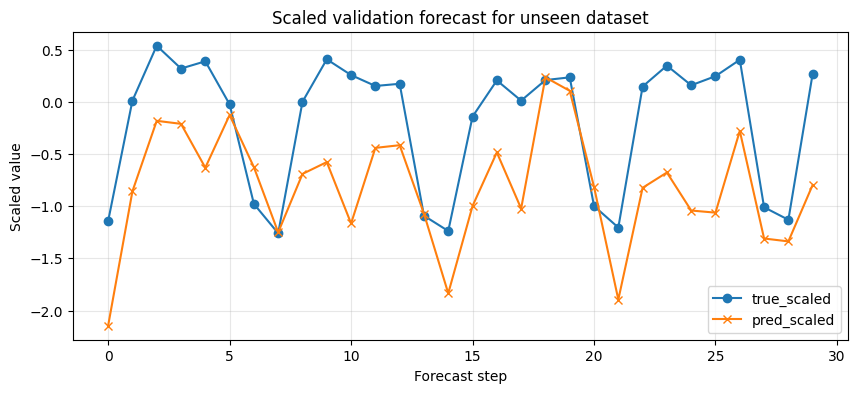

In [51]:
plt.figure(figsize=(10, 4))
plt.plot(true_scaled, label="true_scaled", marker="o")
plt.plot(pred_scaled, label="pred_scaled", marker="x")
plt.title("Scaled validation forecast for unseen dataset")
plt.xlabel("Forecast step")
plt.ylabel("Scaled value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


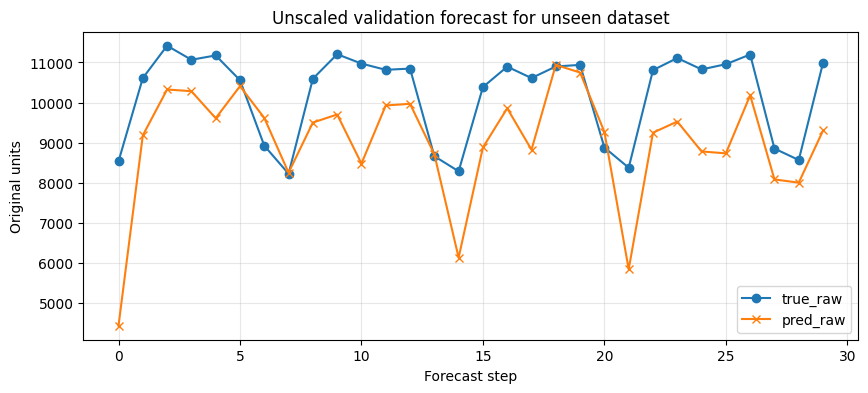

{'support_window_count': 431,
 'observed_validation_points': 30,
 'scaled_relative_l2_error': 1.1850437722351033,
 'unscaled_relative_l2_error': 0.1503723390967379,
 'scaled_relative_mae': 1.352026129849498,
 'unscaled_relative_mae': 0.1235319937798687}

In [52]:
plt.figure(figsize=(10, 4))
plt.plot(true_raw, label="true_raw", marker="o")
plt.plot(pred_raw, label="pred_raw", marker="x")
plt.title("Unscaled validation forecast for unseen dataset")
plt.xlabel("Forecast step")
plt.ylabel("Original units")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

metrics


In [53]:
num_series = X.shape[0]
energy = np.zeros(num_series)
query_context = np.where(unseen.context_mask.astype(bool), unseen.context_scaled, 0.0)

best_entry = None
best_energy = -np.inf
i = 0

for dataset_name in seen_names:
    ds = Dataset(name=dataset_name, term="short", storage_env_var="GIFT_EVAL")
    n_train = sum(1 for _ in ds.training_dataset)
    for series_index in range(min(n_train, max_series_per_dataset)):
        baby_kernel = build_baby_kernel(
            dataset_name=dataset_name,
            term="short",
            series_index=series_index,
            context_length=context_length,
            tau_array=None,
            to_univariate=False,
            alpha=alpha,
            omega=omega,
            normalize=False,
            storage_env_var="GIFT_EVAL",
            transform=transform,
            imputation_strategy=imputation_strategy,
            max_auto_taus=context_length,
            include_current_window=True,
        )
        energy[i] = compute_energy(
            query_context,
            baby_kernel,
            K,
            nugget=lambda_k,
        )
        if energy[i] >= best_energy:
            best_energy = energy[i]
            best_entry = {
                "support_index": i,
                "dataset_name": dataset_name,
                "series_index": series_index,
                "baby_kernel": baby_kernel,
                "energy": float(energy[i]),
            }
        i += 1

if i != num_series:
    raise ValueError(f"Energy scan counted {i} series, but support bank has {num_series} rows.")

idx_selected = best_entry["support_index"]
dataset_selected = best_entry["dataset_name"]
l_selected = best_entry["series_index"]
baby_kernel_selected = best_entry["baby_kernel"]

best_entry


{'support_index': 287,
 'dataset_name': 'restaurant',
 'series_index': 7,
 'baby_kernel': array([[2.04856893, 1.30419491, 0.28089848, ..., 0.        , 0.        ,
         0.        ],
        [1.30419491, 2.20339402, 1.31025679, ..., 0.        , 0.        ,
         0.        ],
        [0.28089848, 1.31025679, 2.20363136, ..., 0.        , 0.        ,
         0.        ],
        ...,
        [0.        , 0.        , 0.        , ..., 2.2032968 , 1.29923264,
         0.25718583],
        [0.        , 0.        , 0.        , ..., 1.29923264, 1.84029659,
         0.52783754],
        [0.        , 0.        , 0.        , ..., 0.25718583, 0.52783754,
         0.51839721]]),
 'energy': 0.012025656252583389}

In [54]:
pruning_results = []
lambda_k_pruned = 10**-5
lambda_gamma_pruned = 10**-5

Gamma_xx_pruned = build_gamma_gram(
    X_scaled[idx_selected,:][None,:],
    time_kernel=baby_kernel_selected,
    lambda_k=lambda_k_pruned,
    masks=X_mask[idx_selected,:][None,:],
)

Gamma_wx_pruned = build_gamma_query(
    unseen.context_scaled,
    X_scaled[idx_selected,:][None,:],
    time_kernel=baby_kernel_selected,
    lambda_k=lambda_k_pruned,
    query_mask=unseen.context_mask,
    context_masks=X_mask[idx_selected,:][None,:],
)

pred_scaled_pruned = predict_future_from_gamma(
    Gamma_wx_pruned,
    Gamma_xx_pruned,
    Y_scaled[idx_selected,:][None,:],
    lambda_gamma=lambda_gamma_pruned,
    target_masks=Y_mask[idx_selected,:][None,:],
)
pred_raw_pruned = inverse_transform_with_stats(
    pred_scaled_pruned,
    loc=unseen.loc,
    scale=unseen.scale,
    transform=unseen.transform,
)


pruning_results = {
        "scaled_relative_l2_error": relative_l2_error(pred_scaled_pruned[observed_future], true_scaled_obs),
        "unscaled_relative_l2_error": relative_l2_error(pred_raw_pruned[observed_future], true_raw_obs),
        "scaled_relative_mae": relative_mae(pred_scaled_pruned[observed_future], true_scaled_obs),
        "unscaled_relative_mae": relative_mae(pred_raw_pruned[observed_future], true_raw_obs)}

pruning_results


{'scaled_relative_l2_error': 0.9998587656719128,
 'unscaled_relative_l2_error': 0.11234749657327664,
 'scaled_relative_mae': 1.0034282229282656,
 'unscaled_relative_mae': 0.08168656291445756}

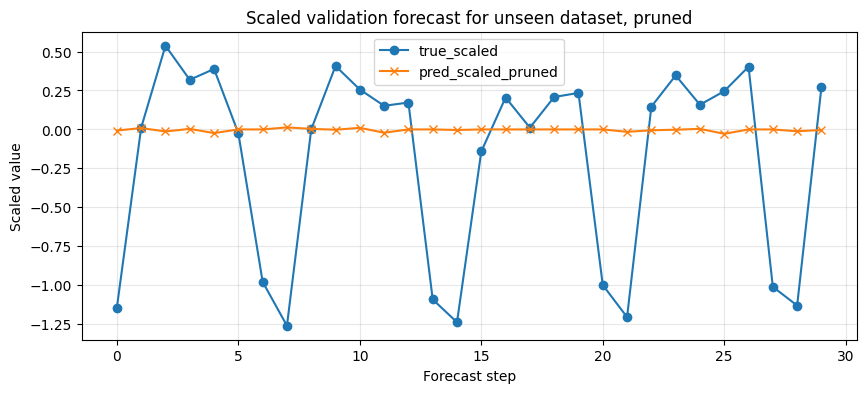

In [55]:
plt.figure(figsize=(10, 4))
plt.plot(true_scaled, label="true_scaled", marker="o")
plt.plot(pred_scaled_pruned, label="pred_scaled_pruned", marker="x")
plt.title("Scaled validation forecast for unseen dataset, pruned")
plt.xlabel("Forecast step")
plt.ylabel("Scaled value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

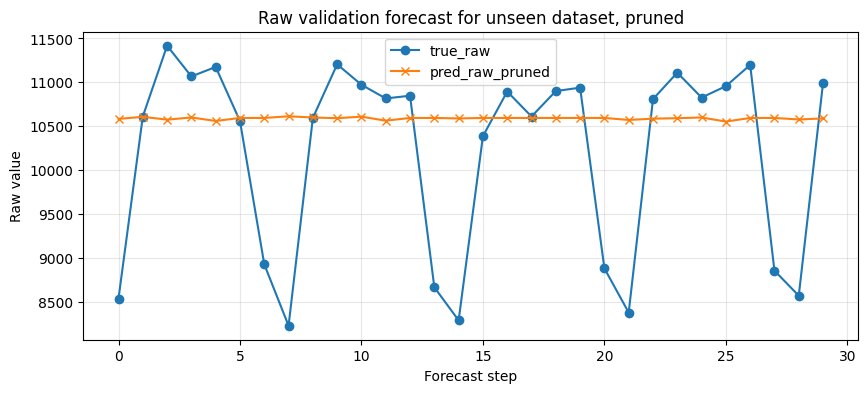

In [56]:
plt.figure(figsize=(10, 4))
plt.plot(true_raw, label="true_raw", marker="o")
plt.plot(pred_raw_pruned, label="pred_raw_pruned", marker="x")
plt.title("Raw validation forecast for unseen dataset, pruned")
plt.xlabel("Forecast step")
plt.ylabel("Raw value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()